<a href="https://colab.research.google.com/github/jksataya/quant-option-pricing-monte-carlo/blob/main/options_pricing_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:

# Project 1: Black-Scholes Options Pricing
# Step 1: Calculate a European call option price

import math
from statistics import NormalDist

# Option inputs
stock_price = 110
strike_price = 100
time_to_expiration = 0.5
risk_free_rate = 0.04
volatility = 0.30

# Standard normal distribution
normal_cdf = NormalDist().cdf

# Calculate d1 and d2
d1 = (
    math.log(stock_price / strike_price)
    + (risk_free_rate + volatility**2 / 2)
    * time_to_expiration
) / (volatility * math.sqrt(time_to_expiration))

d2 = d1 - volatility * math.sqrt(time_to_expiration)

# Black-Scholes call price formula
call_price = (
    stock_price * normal_cdf(d1)
    - strike_price
    * math.exp(-risk_free_rate * time_to_expiration)
    * normal_cdf(d2)
)

print("Stock Price:", stock_price)
print("Strike Price:", strike_price)
print("d1:", round(d1, 4))
print("d2:", round(d2, 4))
print("Call Option Price:", round(call_price, 2))
# Calculate Delta
delta = normal_cdf(d1)

print("Call Option Delta:", round(delta, 4))

Stock Price: 110
Strike Price: 100
d1: 0.6496
d2: 0.4375
Call Option Price: 16.04
Call Option Delta: 0.742


In [7]:

# Calculate Gamma for a European call option

normal_pdf = (
    math.exp(-0.5 * d1**2)
    / math.sqrt(2 * math.pi)
)

gamma = normal_pdf / (
    stock_price * volatility * math.sqrt(time_to_expiration)
)

print("Call Option Gamma:", round(gamma, 4))


Call Option Gamma: 0.0138


In [8]:

# Calculate Vega for a European call option

vega = (
    stock_price
    * normal_pdf
    * math.sqrt(time_to_expiration)
)

print("Call Option Vega:", round(vega, 4))
print("Vega per 1% volatility change:", round(vega / 100, 4))


Call Option Vega: 25.1272
Vega per 1% volatility change: 0.2513


In [9]:

# Calculate Theta for a European call option

theta = (
    -(stock_price * normal_pdf * volatility)
    / (2 * math.sqrt(time_to_expiration))
    - risk_free_rate
    * strike_price
    * math.exp(-risk_free_rate * time_to_expiration)
    * normal_cdf(d2)
)

print("Call Option Theta (per year):", round(theta, 4))
print("Theta per day:", round(theta / 365, 4))


Call Option Theta (per year): -10.1617
Theta per day: -0.0278


In [10]:

# Calculate Rho for a European call option

rho = (
    strike_price
    * time_to_expiration
    * math.exp(-risk_free_rate * time_to_expiration)
    * normal_cdf(d2)
)

print("Call Option Rho:", round(rho, 4))
print("Rho per 1% interest rate change:", round(rho / 100, 4))


Call Option Rho: 32.794
Rho per 1% interest rate change: 0.3279


In [5]:

# Experiment: How does volatility affect a call option?

volatility_values = [0.10, 0.20, 0.30, 0.40, 0.50]

for volatility in volatility_values:

    d1 = (
        math.log(stock_price / strike_price)
        + (risk_free_rate + volatility**2 / 2)
        * time_to_expiration
    ) / (volatility * math.sqrt(time_to_expiration))

    d2 = d1 - volatility * math.sqrt(time_to_expiration)

    call_price = (
        stock_price * normal_cdf(d1)
        - strike_price
        * math.exp(-risk_free_rate * time_to_expiration)
        * normal_cdf(d2)
    )

    print(
        "Volatility:",
        f"{volatility:.0%}",
        "| Call Price:",
        f"${call_price:.2f}"
    )


Volatility: 10% | Call Price: $12.14
Volatility: 20% | Call Price: $13.70
Volatility: 30% | Call Price: $16.04
Volatility: 40% | Call Price: $18.64
Volatility: 50% | Call Price: $21.34


In [12]:

# Project 1: Reusable Black-Scholes Pricing Function

import math
from statistics import NormalDist

normal_cdf = NormalDist().cdf

def black_scholes(stock_price, strike_price, time_to_expiration,
                  risk_free_rate, volatility):

    # Calculate d1 and d2
    d1 = (
        math.log(stock_price / strike_price)
        + (risk_free_rate + volatility**2 / 2)
        * time_to_expiration
    ) / (volatility * math.sqrt(time_to_expiration))

    d2 = d1 - volatility * math.sqrt(time_to_expiration)

    # Calculate call option price
    call_price = (
        stock_price * normal_cdf(d1)
        - strike_price
        * math.exp(-risk_free_rate * time_to_expiration)
        * normal_cdf(d2)
    )

    # Calculate Greeks
    normal_pdf = (
        math.exp(-0.5 * d1**2)
        / math.sqrt(2 * math.pi)
    )

    delta = normal_cdf(d1)

    gamma = normal_pdf / (
        stock_price * volatility * math.sqrt(time_to_expiration)
    )

    # Vega and Rho shown per 1 percentage-point change
    vega = (
        stock_price * normal_pdf
        * math.sqrt(time_to_expiration)
    ) / 100

    theta = (
        -(stock_price * normal_pdf * volatility)
        / (2 * math.sqrt(time_to_expiration))
        - risk_free_rate * strike_price
        * math.exp(-risk_free_rate * time_to_expiration)
        * normal_cdf(d2)
    )

    rho = (
        strike_price * time_to_expiration
        * math.exp(-risk_free_rate * time_to_expiration)
        * normal_cdf(d2)
    ) / 100

    # Return all results
    return {
        "Call Price": call_price,
        "Delta": delta,
        "Gamma": gamma,
        "Vega (per 1%)": vega,
        "Theta (per year)": theta,
        "Theta (per day)": theta / 365,
        "Rho (per 1%)": rho
    }


In [14]:

# Our option inputs

results = black_scholes(
    stock_price=110,
    strike_price=105,
    time_to_expiration=0.25,
    risk_free_rate=0.04,
    volatility=0.25
)

# Display results
for name, value in results.items():
    print(name, ":", round(value, 4))


Call Price : 8.8887
Delta : 0.6966
Gamma : 0.0254
Vega (per 1%) : 0.1922
Theta (per year) : -12.3196
Theta (per day) : -0.0338
Rho (per 1%) : 0.1693


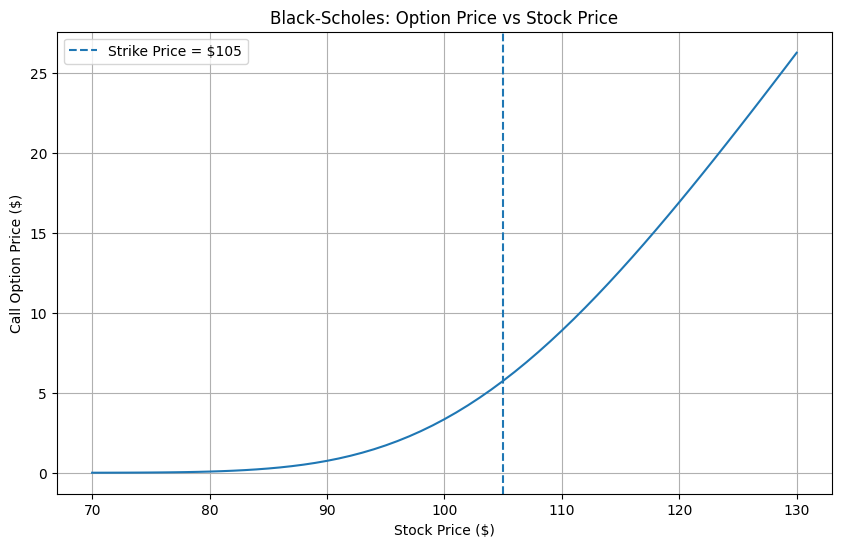

In [16]:

import matplotlib.pyplot as plt

# Stock prices to test
stock_prices = range(70, 131, 1)

# Calculate option prices for each stock price
option_prices = []

for price in stock_prices:

    result = black_scholes(
        stock_price=price,
        strike_price=105,
        time_to_expiration=0.25,
        risk_free_rate=0.04,
        volatility=0.25
    )

    option_prices.append(result["Call Price"])

# Create the chart
plt.figure(figsize=(10, 6))

plt.plot(stock_prices, option_prices)

plt.xlabel("Stock Price ($)")
plt.ylabel("Call Option Price ($)")
plt.title("Black-Scholes: Option Price vs Stock Price")
plt.axvline(
    x=105,
    linestyle="--",
    label="Strike Price = $105"
)

plt.legend()
plt.grid(True)

plt.show()


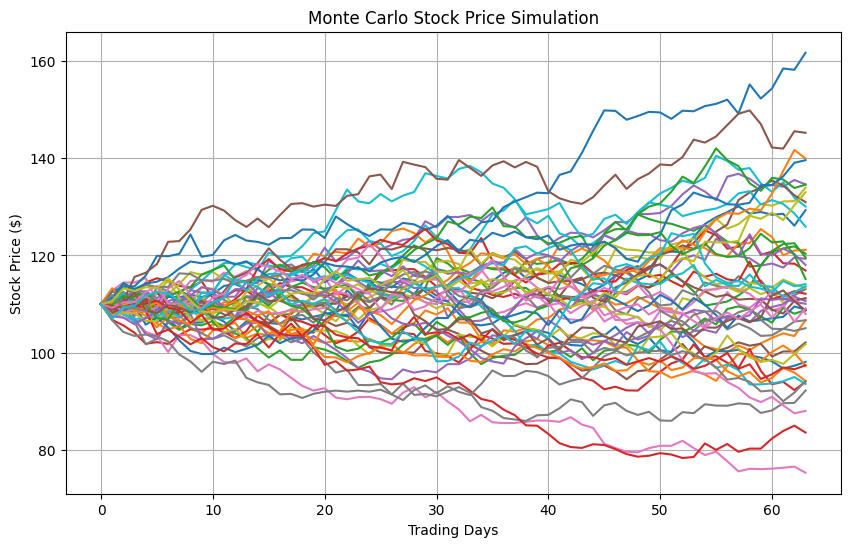

In [17]:

import numpy as np
import matplotlib.pyplot as plt

# Simulation assumptions
initial_price = 110
annual_return = 0.08
volatility = 0.25
time_horizon = 0.25
simulations = 1000
steps = 63

dt = time_horizon / steps

# Simulate stock price paths
np.random.seed(42)

price_paths = np.zeros((steps + 1, simulations))
price_paths[0] = initial_price

for step in range(1, steps + 1):

    random_returns = np.random.normal(
        0,
        1,
        simulations
    )

    price_paths[step] = price_paths[step - 1] * np.exp(
        (annual_return - 0.5 * volatility**2) * dt
        + volatility * np.sqrt(dt) * random_returns
    )

# Plot 50 example paths
plt.figure(figsize=(10, 6))

plt.plot(price_paths[:, :50])

plt.xlabel("Trading Days")
plt.ylabel("Stock Price ($)")
plt.title("Monte Carlo Stock Price Simulation")

plt.grid(True)
plt.show()


In [18]:

# Final stock prices from all simulations
final_prices = price_paths[-1]

# Count simulations that finish above the strike
strike_price = 105

probability_above_strike = np.mean(
    final_prices > strike_price
)

print(
    "Probability stock finishes above $105:",
    round(probability_above_strike * 100, 2),
    "%"
)

print(
    "Average final stock price:",
    round(np.mean(final_prices), 2)
)

print(
    "Median final stock price:",
    round(np.median(final_prices), 2)
)


Probability stock finishes above $105: 68.6 %
Average final stock price: 112.34
Median final stock price: 112.07


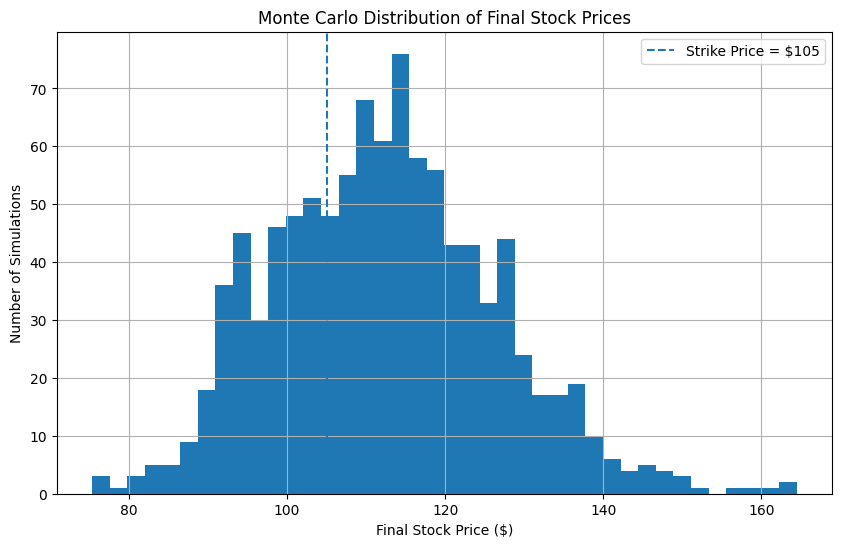

In [19]:

plt.figure(figsize=(10, 6))

plt.hist(final_prices, bins=40)

plt.axvline(
    x=105,
    linestyle="--",
    label="Strike Price = $105"
)

plt.xlabel("Final Stock Price ($)")
plt.ylabel("Number of Simulations")
plt.title("Monte Carlo Distribution of Final Stock Prices")

plt.legend()
plt.grid(True)

plt.show()


In [20]:
# Calculate call option payoff at expiration

strike_price = 105

payoffs = np.maximum(final_prices - strike_price, 0)

# Average payoff across all simulations
expected_payoff = np.mean(payoffs)

# Discount payoff to today's value
discounted_value = expected_payoff * np.exp(
    -risk_free_rate * time_to_expiration
)

print("Average payoff at expiration:", round(expected_payoff, 2))
print("Monte Carlo option value:", round(discounted_value, 2))


Average payoff at expiration: 9.93
Monte Carlo option value: 9.74


In [21]:
# Compare Monte Carlo with Black-Scholes

black_scholes_results = black_scholes(
    stock_price=110,
    strike_price=105,
    time_to_expiration=0.25,
    risk_free_rate=0.04,
    volatility=0.25
)

bs_call_price = black_scholes_results["Call Price"]

print("Monte Carlo Price:", round(discounted_value, 4))
print("Black-Scholes Price:", round(bs_call_price, 4))
print("Pricing Difference:", round(discounted_value - bs_call_price, 4))

Monte Carlo Price: 9.7362
Black-Scholes Price: 8.8887
Pricing Difference: 0.8476
